# Tipologi kondisi pertumbuhan, kerangka

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

Sepuluh kelompok di bawah ini deskriptif. Susunannya mengikuti kombinasi posisi produktivitas, selisih spesifikasi, dan struktur yang diminta. Bukan klaster statistik. Satu provinsi masuk satu kelompok utama. Pilar, struktur tenaga kerja, dan uji skala hasil menjadi penanda sekunder, supaya provinsi yang sama tidak dihitung berkali-kali.

Tiga pembeda tetap terpisah:

- Skala hasil menjawab respons output bila modal dan tenaga kerja naik bersama. Ia tidak menetapkan level produktivitas, keuntungan investasi, atau manfaat bagi penduduk.
- Peringkat menetapkan posisi relatif pada satu cara mengukur residual. Ia tidak menetapkan apakah residual sedang naik.
- Selisih peringkat menetapkan kepekaan posisi terhadap spesifikasi. Ia bukan kenaikan produktivitas akibat perubahan skala.

Jendela peringkat, skala hasil, pilar, dan pangsa disamakan pada 2017–2024. Tenaga kerja 2025 pada berkas konstruksi menyalin 2024, jadi tahun itu tidak masuk estimasi.

Angka 1,54; 2,84; 3,07; 0,65; dan 0,69 pada gambar presentasi tidak dipakai ulang. RTS dihitung di notebook ini.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "tipologi"
OUT.mkdir(parents=True, exist_ok=True)
TAHUN = list(range(2017, 2025))

NAVY, CYAN, RED, TEAL, CREAM, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#797F8C", "#ffffff",
)
WARNA_KAT = {
    "A": "#0E2440", "B": "#D9042B", "C": "#0E7C66", "D": "#1A6F8A",
    "E": "#C47B2B", "F": "#6B4C7A", "G": "#8C3A3A", "H": "#3D6B8C",
    "I": "#2F6F4F", "J": "#A33B73",
}
GARIS = ["#0E2440", "#D9042B", "#0E7C66", "#C47B2B", "#6B4C7A", "#1A6F8A", "#A33B73", "#3D6B8C"]
CMAP = LinearSegmentedColormap.from_list("z", ["#8C3A3A", "#F7F1E8", "#0E2440"])

NAMA = {
    11: "Aceh", 12: "Sumatera Utara", 13: "Sumatera Barat", 14: "Riau",
    15: "Jambi", 16: "Sumatera Selatan", 17: "Bengkulu", 18: "Lampung",
    19: "Kepulauan Bangka Belitung", 21: "Kepulauan Riau",
    31: "DKI Jakarta", 32: "Jawa Barat", 33: "Jawa Tengah", 34: "DI Yogyakarta",
    35: "Jawa Timur", 36: "Banten",
    51: "Bali", 52: "Nusa Tenggara Barat", 53: "Nusa Tenggara Timur",
    61: "Kalimantan Barat", 62: "Kalimantan Tengah", 63: "Kalimantan Selatan",
    64: "Kalimantan Timur", 65: "Kalimantan Utara",
    71: "Sulawesi Utara", 72: "Sulawesi Tengah", 73: "Sulawesi Selatan",
    74: "Sulawesi Tenggara", 75: "Gorontalo", 76: "Sulawesi Barat",
    81: "Maluku", 82: "Maluku Utara", 91: "Papua Barat", 94: "Papua",
}
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}
PULAU = {}
for pulau, kode in {
    "Sumatera": [11, 12, 13, 14, 15, 16, 17, 18, 19, 21],
    "Jawa": [31, 32, 33, 34, 35, 36],
    "Bali-Nusra": [51, 52, 53],
    "Kalimantan": [61, 62, 63, 64, 65],
    "Sulawesi": [71, 72, 73, 74, 75, 76],
    "Maluku-Papua": [81, 82, 91, 94],
}.items():
    for kode_prov in kode:
        PULAU[kode_prov] = pulau

HURUF = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
KELOMPOK = [
    ("Pertanian", ["A"], "#E4D3A8"),
    ("Pertambangan", ["B"], "#D9042B"),
    ("Industri", ["C"], "#0E2440"),
    ("Utilitas dan konstruksi", ["D", "E", "F"], "#46A694"),
    ("Jasa", ["G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"], "#5DD0E6"),
]
# Nama kelompok adalah tipologi deskriptif, bukan hasil klaster.
KELOMPOK_NAMA = {
    "A": "Posisi produktivitas konsisten kuat",
    "B": "IRS dengan konvergensi produktivitas yang belum lengkap",
    "C": "Posisi CRS kuat dengan respons skala yang melemah",
    "D": "Keunggulan produktivitas yang besar pada spesifikasi CRS",
    "E": "Posisi produktivitas lebih kuat pada spesifikasi DRS",
    "F": "Respons skala menurun dengan posisi CRS yang lebih lemah",
    "G": "Dominasi tenaga kerja primer dengan defisit sosial",
    "H": "Kekuatan fondasi tertentu dengan posisi produktivitas lebih lemah",
    "I": "Keunggulan produktivitas moderat pada spesifikasi CRS",
    "J": "Posisi produktivitas lebih rendah dengan selisih peringkat terbatas",
}
ANGGOTA = {
    "A": [31, 14],
    "B": [82, 72],
    "C": [64, 21],
    "D": [65, 19, 91],
    "E": [33, 32, 35, 73, 16, 12, 36],
    "F": [18, 61, 53, 52, 13],
    "G": [94],
    "H": [34, 81, 11],
    "I": [15, 62, 63, 71, 74],
    "J": [17, 75, 76, 51],
}
# Klaim RTS yang tertulis pada nama kelompok. Kosong = kelompok tidak mengunci satu kelas.
KLAIM = {"B": "IRS", "C": "DRS", "D": "memuat 1", "F": "DRS", "G": "DRS", "I": "memuat 1", "J": "memuat 1"}
PILAR = [
    ("pil_pendidikan", "Pendidikan"), ("pil_equity", "Ekuitas"),
    ("pil_institusi", "Institusi"), ("pil_konektivitas", "Konektivitas"),
    ("pil_lingkungan", "Lingkungan"), ("pil_keamanan", "Keamanan"),
]

plt.rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def simpan(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=KERTAS)
    print(path.relative_to(ROOT))
    plt.show()

def bersih(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid)
    ax.grid(axis=("x" if grid == "y" else "y"), visible=False)

def koma(x, n=2, tanda=False):
    if pd.isna(x):
        return "—"
    teks = f"{x:+.{n}f}" if tanda else f"{x:.{n}f}"
    return teks.replace(".", ",")

def ols(y, X):
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ b
    dof = len(y) - X.shape[1]
    s2 = float(resid @ resid) / dof
    V = s2 * np.linalg.inv(X.T @ X)
    return b, V, dof

def se_lin(V, c):
    c = np.asarray(c, float)
    return float(np.sqrt(c @ V @ c))


## Data dan estimasi

Residual dari `TFP Provinsi 2017-2025.xlsx`. Upah, kemiskinan, TPT, dan PMA+PMDN dari panel eval. Pilar dari lembar kovariat.


In [2]:
tfp = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="tfp")
sek = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="sektor")
kov = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="kovariat")
ev = pd.read_excel(ROOT / "01 Data/TFP/output/eval/eval_panel.xlsx", sheet_name="panel")
for df in (tfp, sek, kov, ev):
    df["Code_Prov"] = df["Code_Prov"].astype(int)
    df["Year"] = df["Year"].astype(int)

d = tfp[tfp.Year.isin(TAHUN)].copy()
assert set(d.Code_Prov) == set(NAMA)
assert d.groupby("Code_Prov").size().eq(8).all()

# Elastisitas nasional: FE dua arah, pembanding pada gambar skala. Bukan rata-rata RTS provinsi.
dm = d.copy()
for col in ("log_Y", "log_K", "log_L"):
    dm[col] = (
        d[col]
        - d.groupby("Code_Prov")[col].transform("mean")
        - d.groupby("Year")[col].transform("mean")
        + d[col].mean()
    )
b_fe, *_ = ols(dm.log_Y, np.column_stack([dm.log_K, dm.log_L]))
rts_fe = float(b_fe.sum())
print(f"FE dua arah  b1 {b_fe[0]:.3f}  b2 {b_fe[1]:.3f}  jumlah {rts_fe:.3f}")

# Lima kelompok sektor. Pangsa dihitung dari jumlah 17 sektor.
bagian = []
for nama, huruf, _warna in KELOMPOK:
    va = sek[[f"{h}_ADHK" for h in huruf]].sum(axis=1)
    tk = sek[[f"{h}_TenagaKerja" for h in huruf]].sum(axis=1)
    bagian.append(pd.DataFrame({
        "Code_Prov": sek.Code_Prov.to_numpy(), "Year": sek.Year.to_numpy(),
        "kelompok": nama, "va": va.to_numpy(), "tk": tk.to_numpy(),
    }))
kel = pd.concat(bagian, ignore_index=True)
kel = kel[kel.Year.isin(TAHUN)].copy()
total = kel.groupby(["Code_Prov", "Year"], as_index=False)[["va", "tk"]].sum()
kel = kel.merge(total.rename(columns={"va": "va_tot", "tk": "tk_tot"}), on=["Code_Prov", "Year"])
kel["share_va"] = kel.va / kel.va_tot
kel["share_tk"] = kel.tk / kel.tk_tot
kel["lp"] = np.where(kel.tk > 0, kel.va * 1000 / kel.tk, np.nan)

ev = ev[ev.Year.isin(TAHUN)].copy()
ev["upah_riil"] = ev.upah_rata / ev.deflator * 100
ev["tpt"] = ev.TPT_Prov * 100 if ev.TPT_Prov.median() < 1 else ev.TPT_Prov
ev["p0p"] = ev.p0 * 100 if ev.p0.median() < 1 else ev.p0
for h in HURUF:
    ev[f"inv_{h}"] = ev[f"{h}_PMA"].fillna(0) + ev[f"{h}_PMDN"].fillna(0)
ev["inv_primer"] = ev.inv_A + ev.inv_B
ev["inv_sekunder"] = ev[[f"inv_{h}" for h in "CDEF"]].sum(axis=1)
ev["inv_tersier"] = ev[[f"inv_{h}" for h in HURUF if h not in list("ABCDEF")]].sum(axis=1)
ev["inv_tot"] = ev[[f"inv_{h}" for h in HURUF]].sum(axis=1)

panel = d.merge(
    ev[["Code_Prov", "Year", "upah_riil", "tpt", "p0p", "inv_primer", "inv_sekunder", "inv_tersier", "inv_tot"]],
    on=["Code_Prov", "Year"], how="left",
).merge(
    kov.loc[kov.Year.isin(TAHUN), [
        "Code_Prov", "Year", "lama_sekolah_mean", "gini", "jalan_mantap_pc",
        "pilar_pendidikan", "pilar_equity", "pilar_institusi", "pilar_konektivitas",
        "pilar_lingkungan", "pilar_keamanan",
    ]],
    on=["Code_Prov", "Year"], how="left",
)
panel["yl"] = panel.pdrb_adhk * 1000 / panel.labours_total
panel["kl"] = panel.pmtb_adhk * 1000 / panel.labours_total
panel["short"] = panel.Code_Prov.map(SHORT)
assert panel.upah_riil.notna().all()


FE dua arah  b1 0.387  b2 0.193  jumlah 0.580


In [3]:
# RTS provinsi: log Y = a + b1 log K + b2 log L, delapan tahun.
# Selang 95% pada b1+b2. IRS hanya jika batas bawah > 1, DRS hanya jika batas atas < 1.
# K adalah arus PMTB, bukan stok. b1 dan b2 terpisah tidak stabil bila keduanya bergerak bersama.
baris = []
for code, g in d.groupby("Code_Prov"):
    g = g.sort_values("Year")
    b, V, dof = ols(g.log_Y, np.column_stack([np.ones(len(g)), g.log_K, g.log_L]))
    tcrit = float(stats.t.ppf(0.975, dof))
    rts = float(b[1] + b[2])
    se = se_lin(V, [0, 1, 1])
    lo, hi = rts - tcrit * se, rts + tcrit * se
    if lo > 1:
        uji = "IRS"
    elif hi < 1:
        uji = "DRS"
    else:
        uji = "memuat 1"
    rec = {
        "code": int(code), "b1": float(b[1]), "se_b1": se_lin(V, [0, 1, 0]),
        "b2": float(b[2]), "se_b2": se_lin(V, [0, 0, 1]),
        "rts": rts, "se_rts": se, "rts_lo": lo, "rts_hi": hi, "uji": uji,
        "corr_kl": float(g.log_K.corr(g.log_L)),
    }
    for col, dest in (("logtfp_it", "drs"), ("logtfp_it_crs", "crs")):
        bt, Vt, doft = ols(g[col], np.column_stack([np.ones(len(g)), g.Year]))
        tt = float(stats.t.ppf(0.975, doft))
        se_t = se_lin(Vt, [0, 1])
        rec[f"tfp_{dest}"] = float(g[col].mean())
        rec[f"tren_{dest}"] = float(bt[1])
        rec[f"tren_{dest}_lo"] = float(bt[1] - tt * se_t)
        rec[f"tren_{dest}_hi"] = float(bt[1] + tt * se_t)
    baris.append(rec)
prov = pd.DataFrame(baris)
print("korelasi median log K dan log L", round(prov.corr_kl.median(), 2))
print(prov.uji.value_counts().to_string())


korelasi median log K dan log L 0.9
uji
memuat 1    23
IRS         10
DRS          1


In [4]:
rata = kel.groupby(["Code_Prov", "kelompok"], as_index=False)[["share_tk", "share_va"]].mean()
lebar_tk = rata.pivot(index="Code_Prov", columns="kelompok", values="share_tk")
lebar_va = rata.pivot(index="Code_Prov", columns="kelompok", values="share_va")
lp24 = kel[kel.Year == 2024].pivot(index="Code_Prov", columns="kelompok", values="lp")
peta = {
    "Pertanian": "A", "Pertambangan": "B", "Industri": "C",
    "Utilitas dan konstruksi": "def", "Jasa": "jasa",
}
saham = pd.DataFrame({"code": lebar_tk.index.astype(int)})
for sumber, akhir in peta.items():
    saham[f"tk_{akhir}"] = lebar_tk[sumber].to_numpy()
    saham[f"va_{akhir}"] = lebar_va[sumber].to_numpy()
saham["tk_primer"] = saham.tk_A + saham.tk_B
saham["tk_sekunder"] = saham.tk_C + saham.tk_def
saham["tk_tersier"] = saham.tk_jasa
saham["va_primer"] = saham.va_A + saham.va_B
saham["va_sekunder"] = saham.va_C + saham.va_def
saham["va_tersier"] = saham.va_jasa
saham["lp_A"] = lp24["Pertanian"].to_numpy()
saham["lp_B"] = lp24["Pertambangan"].to_numpy()
saham["lp_jasa"] = lp24["Jasa"].to_numpy()

hhi = []
sek_t = sek[sek.Year.isin(TAHUN)]
for code, g in sek_t.groupby("Code_Prov"):
    va = g[[f"{h}_ADHK" for h in HURUF]].sum()
    s = va / va.sum()
    hhi.append({"code": int(code), "hhi_va": float((s ** 2).sum())})

ujung = panel.pivot(index="Code_Prov", columns="Year")
tingkat = pd.DataFrame({
    "code": ujung.index.astype(int),
    "yl17": ujung[("yl", 2017)].to_numpy(), "yl24": ujung[("yl", 2024)].to_numpy(),
    "kl17": ujung[("kl", 2017)].to_numpy(), "kl24": ujung[("kl", 2024)].to_numpy(),
    "upah17": ujung[("upah_riil", 2017)].to_numpy(), "upah24": ujung[("upah_riil", 2024)].to_numpy(),
    "p0_17": ujung[("p0p", 2017)].to_numpy(), "p0_24": ujung[("p0p", 2024)].to_numpy(),
})
rata_lain = panel.groupby("Code_Prov", as_index=False).agg(
    tpt=("tpt", "mean"), sekolah=("lama_sekolah_mean", "mean"), gini=("gini", "mean"),
    jalan=("jalan_mantap_pc", "mean"),
    pil_pendidikan=("pilar_pendidikan", "mean"), pil_equity=("pilar_equity", "mean"),
    pil_institusi=("pilar_institusi", "mean"), pil_konektivitas=("pilar_konektivitas", "mean"),
    pil_lingkungan=("pilar_lingkungan", "mean"), pil_keamanan=("pilar_keamanan", "mean"),
    inv_primer=("inv_primer", "sum"), inv_sekunder=("inv_sekunder", "sum"),
    inv_tersier=("inv_tersier", "sum"), inv_tot=("inv_tot", "sum"),
)
rata_lain["code"] = rata_lain.Code_Prov.astype(int)
for col in ("inv_primer", "inv_sekunder", "inv_tersier"):
    rata_lain[col] = rata_lain[col] / rata_lain.inv_tot

# Shift-share output per pekerja, 2017 ke 2024, lima kelompok.
shift = []
for code, g in kel.groupby("Code_Prov"):
    a = g[g.Year == 2017].set_index("kelompok")
    b = g[g.Year == 2024].set_index("kelompok")
    s0, s1 = a.share_tk, b.share_tk
    p0, p1 = a.va / a.tk, b.va / b.tk
    within = float((s0 * (p1 - p0)).sum())
    between = float((p0 * (s1 - s0)).sum())
    dynamic = float(((s1 - s0) * (p1 - p0)).sum())
    total = float((s1 * p1).sum() - (s0 * p0).sum())
    assert abs(within + between + dynamic - total) < 1e-6
    shift.append({
        "code": int(code),
        "ss_within": within * 1000, "ss_between": between * 1000,
        "ss_dynamic": dynamic * 1000, "ss_total": total * 1000,
    })

prov = (
    prov.merge(saham, on="code")
    .merge(pd.DataFrame(hhi), on="code")
    .merge(tingkat, on="code")
    .merge(rata_lain.drop(columns=["Code_Prov", "inv_tot"]), on="code")
    .merge(pd.DataFrame(shift), on="code")
)
prov["nama"] = prov.code.map(NAMA)
prov["short"] = prov.code.map(SHORT)
prov["pulau"] = prov.code.map(PULAU)
prov["rank_drs"] = prov.tfp_drs.rank(ascending=False, method="min").astype(int)
prov["rank_crs"] = prov.tfp_crs.rank(ascending=False, method="min").astype(int)
prov["selisih"] = prov.rank_drs - prov.rank_crs
prov["struktur"] = np.where(
    (prov.tk_tersier >= prov.tk_primer) & (prov.tk_tersier >= prov.tk_sekunder), "tersier",
    np.where(prov.tk_primer >= prov.tk_sekunder, "primer", "sekunder"),
)
nama_kel = [n for n, _, _ in KELOMPOK]
prov["tk_terbesar"] = [nama_kel[i] for i in prov[["tk_A", "tk_B", "tk_C", "tk_def", "tk_jasa"]].to_numpy().argmax(1)]
prov["va_terbesar"] = [nama_kel[i] for i in prov[["va_A", "va_B", "va_C", "va_def", "va_jasa"]].to_numpy().argmax(1)]

kode_kat, urut = [], []
for huruf, anggota in ANGGOTA.items():
    for i, code in enumerate(anggota):
        kode_kat.append((code, huruf))
        urut.append((code, list(KELOMPOK_NAMA).index(huruf) * 100 + i))
prov = prov.merge(pd.DataFrame(kode_kat, columns=["code", "kode_kat"]), on="code")
prov = prov.merge(pd.DataFrame(urut, columns=["code", "urut"]), on="code")
prov["kategori"] = prov.kode_kat.map(KELOMPOK_NAMA)
prov["klaim"] = prov.kode_kat.map(KLAIM)
prov["uji_sesuai"] = prov.klaim.isna() | (prov.uji == prov.klaim)
assert set(prov.code) == set(NAMA)
assert prov.kode_kat.nunique() == 10

rendah, tinggi = [], []
for _, r in prov.iterrows():
    bawah, atas = [], []
    for col, lab in PILAR:
        if int(prov[col].rank(ascending=True, method="min").loc[r.name]) <= 5:
            bawah.append(lab.lower())
        if int(prov[col].rank(ascending=False, method="min").loc[r.name]) <= 5:
            atas.append(lab.lower())
    rendah.append(", ".join(bawah))
    tinggi.append(", ".join(atas))
prov["bawah"] = rendah
prov["atas"] = tinggi
prov = prov.sort_values("urut").reset_index(drop=True)
print("34 provinsi,", prov.groupby("kode_kat").size().sum(), "baris")


34 provinsi, 34 baris


## Tabel karakteristik

Satu baris satu provinsi. Level residual disimpan bersama peringkat, karena selisih peringkat bisa besar walaupun skornya berdekatan.

`Uji RTS` memakai selang 95% regresi provinsi. Nama kelompok yang memuat kata IRS atau DRS tidak otomatis lolos uji itu. Baris yang tidak sesuai dicetak di bawah tabel.


In [5]:
tampil = prov[[
    "kode_kat", "nama", "uji", "rts", "rts_lo", "rts_hi",
    "rank_drs", "rank_crs", "selisih", "tfp_crs", "tren_crs",
    "tk_primer", "tk_tersier", "uji_sesuai",
]].copy()
tampil["rts"] = tampil.rts.round(2)
tampil["rts_lo"] = tampil.rts_lo.round(2)
tampil["rts_hi"] = tampil.rts_hi.round(2)
tampil["tfp_crs"] = tampil.tfp_crs.round(3)
tampil["tren_crs"] = (100 * tampil.tren_crs).round(2)
tampil["tk_primer"] = (100 * tampil.tk_primer).round(1)
tampil["tk_tersier"] = (100 * tampil.tk_tersier).round(1)
tampil = tampil.rename(columns={
    "kode_kat": "Kelompok", "nama": "Provinsi", "uji": "Uji RTS",
    "rts": "RTS", "rts_lo": "Bawah", "rts_hi": "Atas",
    "rank_drs": "Peringkat DRS", "rank_crs": "Peringkat CRS", "selisih": "Selisih",
    "tfp_crs": "Residual CRS", "tren_crs": "Tren CRS",
    "tk_primer": "TK primer %", "tk_tersier": "TK tersier %",
    "uji_sesuai": "Sesuai nama kelompok",
})
try:
    from IPython.display import display
    display(tampil)
except Exception:
    print(tampil.to_string(index=False))

print("\nUji RTS tidak sama dengan klaim pada nama kelompok:")
beda = prov.loc[~prov.uji_sesuai, ["short", "kode_kat", "klaim", "uji", "rts", "rts_lo", "rts_hi"]]
print(beda.to_string(index=False) if len(beda) else "tidak ada")

lembar = prov[[
    "code", "nama", "pulau", "kode_kat", "kategori", "uji", "klaim", "uji_sesuai",
    "rts", "se_rts", "rts_lo", "rts_hi", "b1", "se_b1", "b2", "se_b2", "corr_kl",
    "tfp_drs", "tfp_crs", "rank_drs", "rank_crs", "selisih",
    "tren_drs", "tren_drs_lo", "tren_drs_hi", "tren_crs", "tren_crs_lo", "tren_crs_hi",
    "yl17", "yl24", "kl17", "kl24",
    "tk_primer", "tk_sekunder", "tk_tersier", "va_primer", "va_sekunder", "va_tersier",
    "tk_A", "tk_B", "va_A", "va_B", "hhi_va", "tk_terbesar", "va_terbesar", "struktur",
    "upah17", "upah24", "tpt", "p0_17", "p0_24", "sekolah", "gini", "jalan",
    "pil_pendidikan", "pil_equity", "pil_institusi", "pil_konektivitas", "pil_lingkungan", "pil_keamanan",
    "bawah", "atas", "inv_primer", "inv_sekunder", "inv_tersier",
    "ss_within", "ss_between", "ss_dynamic", "ss_total", "lp_A", "lp_B", "lp_jasa",
]].copy()
metode = pd.DataFrame({
    "butir": ["Jendela", "Kelompok", "Residual", "Peringkat", "Selisih", "RTS provinsi", "RTS nasional", "Modal", "Upah", "Shift-share", "Bukan temuan"],
    "isi": [
        "2017–2024. Tenaga kerja 2025 menyalin 2024, jadi tidak masuk estimasi.",
        "A–J tipologi deskriptif yang diminta, bukan klaster. Satu provinsi satu kelompok utama.",
        "Log residual konstruksi. Jangan dieksponenkan.",
        "1 = rata-rata residual tertinggi, dihitung dari tabel.",
        "Peringkat DRS minus peringkat CRS. Positif = posisi relatif lebih tinggi pada CRS. Bukan kenaikan produktivitas.",
        "OLS terpisah, selang t, derajat bebas 5. IRS bila batas bawah > 1. DRS bila batas atas < 1.",
        f"FE dua arah: b1 {b_fe[0]:.3f}, b2 {b_fe[1]:.3f}, jumlah {rts_fe:.3f}.",
        "Arus PMTB riil per pekerja, bukan stok dan bukan utilisasi.",
        "Upah bulanan dibagi deflator panel eval, dinyatakan pada deflator = 100.",
        "Perubahan nilai tambah per pekerja diurai within, between, dan interaksi. Juta rupiah per pekerja.",
        "Pertanyaan investasi pada notebook kelompok bukan efek yang sudah terbukti. Pemasok lokal, status formal, dan emisi fisik tidak ada di panel ini.",
    ],
})
berkas = OUT / "Karakteristik Provinsi 2017-2024.xlsx"
with pd.ExcelWriter(berkas, engine="openpyxl") as w:
    lembar.to_excel(w, sheet_name="provinsi", index=False)
    metode.to_excel(w, sheet_name="metode", index=False)
prov.to_csv(OUT / "tipologi_prov.csv", index=False)
panel.to_csv(OUT / "tipologi_panel.csv", index=False)
kel.to_csv(OUT / "tipologi_kelompok.csv", index=False)
print(berkas.relative_to(ROOT))


,Kelompok,Provinsi,Uji RTS,RTS,Bawah,Atas,Peringkat DRS,Peringkat CRS,Selisih,Residual CRS,Tren CRS,TK primer %,TK tersier %,Sesuai nama kelompok
0,A,DKI Jakarta,memuat 1,2.49,0.55,4.44,1,1,0,-0.112,2.47,0.8,82.6,True
1,A,Riau,DRS,0.85,0.76,0.94,6,5,1,-0.481,0.71,38.9,47.3,True
2,B,Maluku Utara,IRS,3.20,2.10,4.30,34,30,4,-1.253,1.55,36.9,43.6,True
3,B,Sulawesi Tengah,memuat 1,3.06,0.14,5.97,19,15,4,-0.902,3.84,43.0,43.1,False
4,C,Kalimantan Timur,memuat 1,0.80,0.57,1.02,4,2,2,-0.125,-0.80,27.3,58.5,False
5,C,Kepulauan Riau,memuat 1,0.99,0.81,1.17,13,6,7,-0.559,0.45,8.7,58.1,False
6,D,Kalimantan Utara,memuat 1,1.36,0.50,2.22,23,4,19,-0.421,1.54,32.7,53.3,True
7,D,Kepulauan Bangka Belitung,memuat 1,1.19,0.10,2.28,26,8,18,-0.769,1.39,42.6,44.8,True
8,D,Papua Barat,memuat 1,0.62,-0.64,1.88,17,3,14,-0.353,1.30,35.3,52.8,True
9,E,Jawa Tengah,memuat 1,1.17,0.84,1.50,5,23,-18,-1.064,0.90,22.3,45.9,True



Uji RTS tidak sama dengan klaim pada nama kelompok:
    short kode_kat    klaim      uji      rts   rts_lo   rts_hi
  Sulteng        B      IRS memuat 1 3.059816 0.144916 5.974716
   Kaltim        C      DRS memuat 1 0.796474 0.573124 1.019823
    Kepri        C      DRS memuat 1 0.990864 0.811720 1.170007
  Lampung        F      DRS      IRS 1.253957 1.032369 1.475544
   Kalbar        F      DRS memuat 1 1.145600 0.719346 1.571853
      NTT        F      DRS      IRS 1.312615 1.089404 1.535827
      NTB        F      DRS memuat 1 0.551389 0.065854 1.036923
   Sumbar        F      DRS memuat 1 1.124327 0.908483 1.340170
    Papua        G      DRS memuat 1 0.875483 0.162588 1.588377
    Sulut        I memuat 1      IRS 1.507110 1.179540 1.834680
   Sultra        I memuat 1      IRS 1.548680 1.166761 1.930599
 Bengkulu        J memuat 1      IRS 1.399611 1.194377 1.604845
Gorontalo        J memuat 1      IRS 1.507848 1.347699 1.667997
01 Data/TFP/output/tipologi/Karakteristik Provinsi 

## Skala dan posisi produktivitas

Sumbu mendatar adalah estimasi RTS. Sumbu tegak adalah level residual CRS, bukan peringkat. Warna adalah kelompok. Segitiga adalah selang yang tidak memuat 1. Lingkaran kosong adalah selang yang memuat 1. Garis putus-putus adalah jumlah elastisitas FE dua arah nasional.

Jakarta dan Maluku Utara tidak berbagi cerita investasi hanya karena titik RTS-nya sama-sama bisa berada di atas 1. Posisi tegaknya berbeda.


01 Data/TFP/output/tipologi/tip_01_skala_produktivitas.png


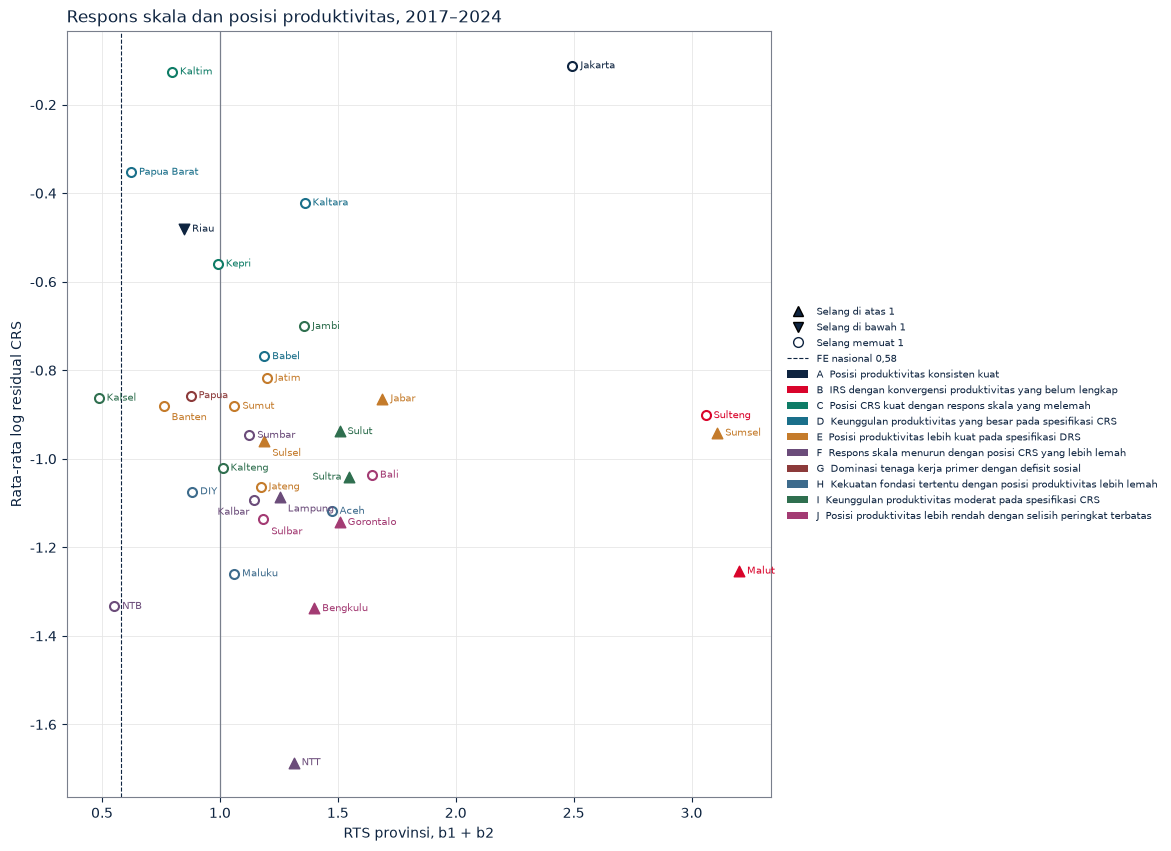

In [6]:
def susun_label(ax, baris):
    ax.figure.canvas.draw()
    item = []
    for x, y, teks, warna in baris:
        px, py = ax.transData.transform((x, y))
        item.append((px, py, x, y, teks, warna))
    item.sort(key=lambda r: -r[1])
    terpakai = []
    for px, py, x, y, teks, warna in item:
        lebar = 4.8 * len(teks) + 6
        ketemu = None
        for langkah in range(8):
            for tanda in (1, -1):
                dy = 0 if langkah == 0 else tanda * langkah * 12
                for dx in (8, -lebar - 2):
                    qx, qy = px + dx, py + dy
                    if qy < ax.bbox.y0 + 4 or qy > ax.bbox.y1 - 8:
                        continue
                    if all(abs(qx - ux) > max(lebar, uw) or abs(qy - uy) > 11 for ux, uy, uw in terpakai):
                        ketemu = (qx, qy)
                        break
                if ketemu:
                    break
            if ketemu:
                break
        if ketemu is None:
            ketemu = (px + 8, py + 4)
        lx, ly = ketemu
        terpakai.append((lx, ly, lebar))
        tx, ty = ax.transData.inverted().transform((lx, ly))
        jauh = abs(lx - px) > 14 or abs(ly - py) > 14
        ax.annotate(
            teks, (x, y), xytext=(tx, ty), textcoords="data",
            fontsize=7, color=warna, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=warna, lw=0.35) if jauh else None,
        )

fig, ax = plt.subplots(figsize=(11.6, 8.4), layout="constrained")
baris_label = []
for r in prov.itertuples(index=False):
    warna = WARNA_KAT[r.kode_kat]
    if r.uji == "memuat 1":
        ax.scatter(r.rts, r.tfp_crs, s=42, facecolors="white", edgecolors=warna, linewidths=1.5, zorder=3)
    else:
        ax.scatter(r.rts, r.tfp_crs, s=58, c=warna, marker="^" if r.uji == "IRS" else "v", zorder=3)
    baris_label.append((r.rts, r.tfp_crs, r.short, warna))
ax.axvline(1, color=GRAY, lw=0.9)
ax.axvline(rts_fe, color=NAVY, lw=0.8, ls="--")
ax.set_xlabel("RTS provinsi, b1 + b2")
ax.set_ylabel("Rata-rata log residual CRS")
ax.set_title("Respons skala dan posisi produktivitas, 2017–2024", loc="left", color=NAVY)
pegangan = [
    Line2D([0], [0], marker="^", color="none", markerfacecolor=NAVY, markersize=7, label="Selang di atas 1"),
    Line2D([0], [0], marker="v", color="none", markerfacecolor=NAVY, markersize=7, label="Selang di bawah 1"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white", markeredgecolor=NAVY, markersize=7, label="Selang memuat 1"),
    Line2D([0], [0], color=NAVY, lw=0.8, ls="--", label=f"FE nasional {koma(rts_fe, 2)}"),
]
pegangan += [Patch(facecolor=WARNA_KAT[k], edgecolor="none", label=f"{k}  {KELOMPOK_NAMA[k]}") for k in KELOMPOK_NAMA]
ax.legend(handles=pegangan, fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5))
susun_label(ax, baris_label)
simpan(fig, "tip_01_skala_produktivitas.png")


## Profil kelompok

Warna adalah z terhadap 34 provinsi. Nilai asli ada di tabel. Baris dikelompokkan supaya pengecualian di dalam kelompok dan kemiripan antarkelompok terlihat bersama.

Kelompok J sengaja tidak dirata-ratakan: Bali berbasis jasa, tiga provinsi lain tidak.


01 Data/TFP/output/tipologi/tip_02_heatmap_profil.png


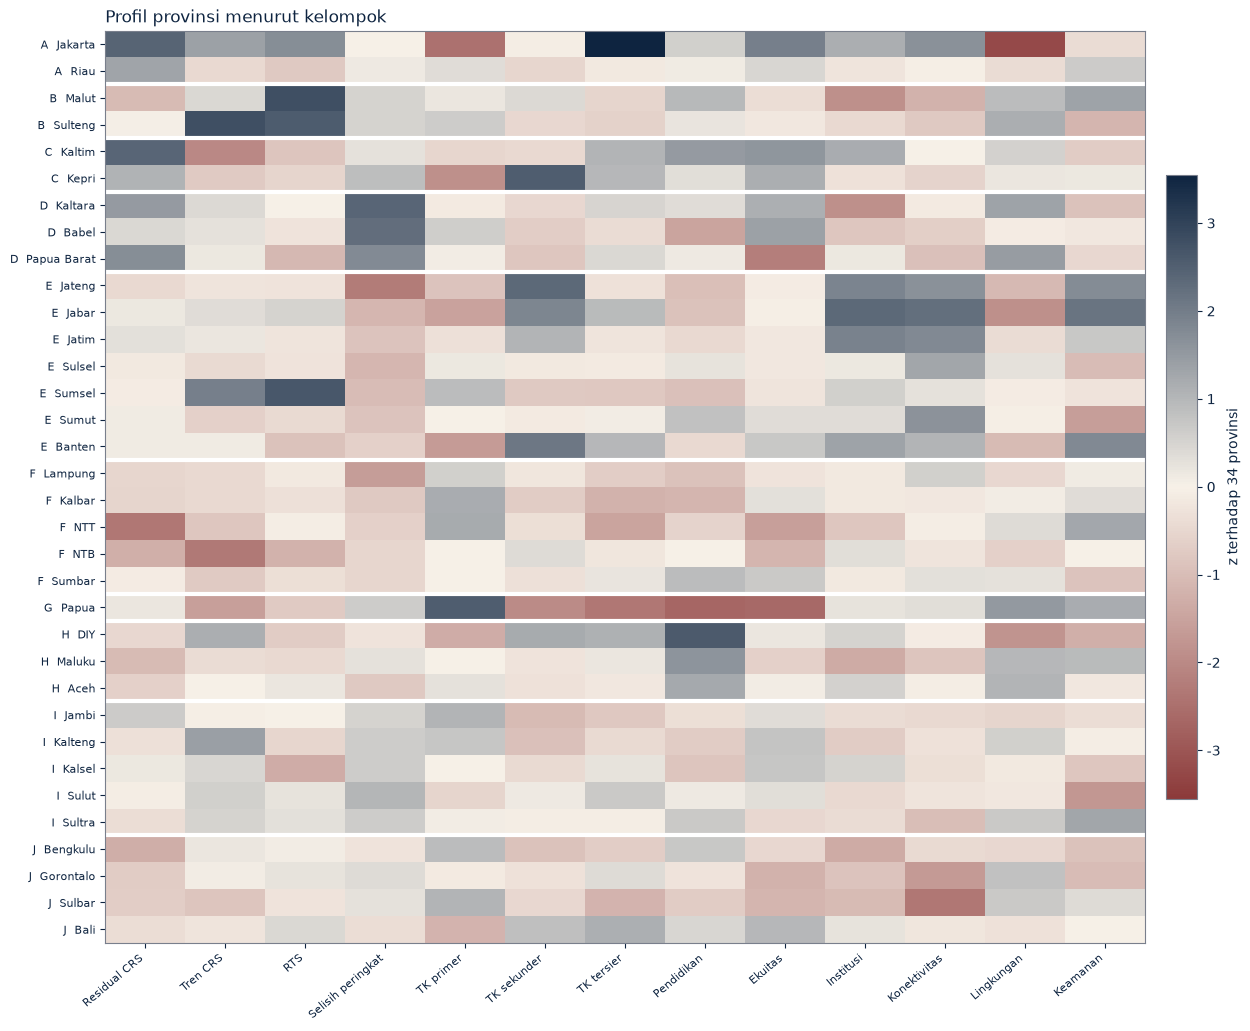

In [7]:
df = prov.sort_values("urut")
kolom = [
    ("tfp_crs", "Residual CRS"), ("tren_crs", "Tren CRS"), ("rts", "RTS"),
    ("selisih", "Selisih peringkat"), ("tk_primer", "TK primer"),
    ("tk_sekunder", "TK sekunder"), ("tk_tersier", "TK tersier"),
    ("pil_pendidikan", "Pendidikan"), ("pil_equity", "Ekuitas"),
    ("pil_institusi", "Institusi"), ("pil_konektivitas", "Konektivitas"),
    ("pil_lingkungan", "Lingkungan"), ("pil_keamanan", "Keamanan"),
]
def z(s):
    return (s - s.mean()) / s.std(ddof=0)
mat = np.column_stack([z(df[c]).to_numpy() for c, _ in kolom])
fig, ax = plt.subplots(figsize=(12.4, 10.2), layout="constrained")
batas = np.nanmax(np.abs(mat))
im = ax.imshow(mat, cmap=CMAP, vmin=-batas, vmax=batas, aspect="auto")
ax.set_xticks(range(len(kolom)))
ax.set_xticklabels([lab for _, lab in kolom], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(df)))
ax.set_yticklabels([f"{r.kode_kat}  {r.short}" for r in df.itertuples(index=False)], fontsize=8)
sebelum = None
for i, r in enumerate(df.itertuples(index=False)):
    if sebelum and r.kode_kat != sebelum:
        ax.axhline(i - 0.5, color=KERTAS, lw=3)
    sebelum = r.kode_kat
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="z terhadap 34 provinsi")
ax.set_title("Profil provinsi menurut kelompok", loc="left", color=NAVY)
simpan(fig, "tip_02_heatmap_profil.png")


## Di dalam sektor atau pindah sektor

Perubahan nilai tambah per pekerja dari 2017 ke 2024 diurai menjadi kenaikan di dalam sektor dan pergeseran tenaga kerja antarsektor. Satuan juta rupiah per pekerja. Komponen interaksi ada di tabel, tidak digambar.

Ini memisahkan peningkatan di dalam kegiatan yang sudah ada dari perubahan campuran ekonomi.


01 Data/TFP/output/tipologi/tip_03_shiftshare.png


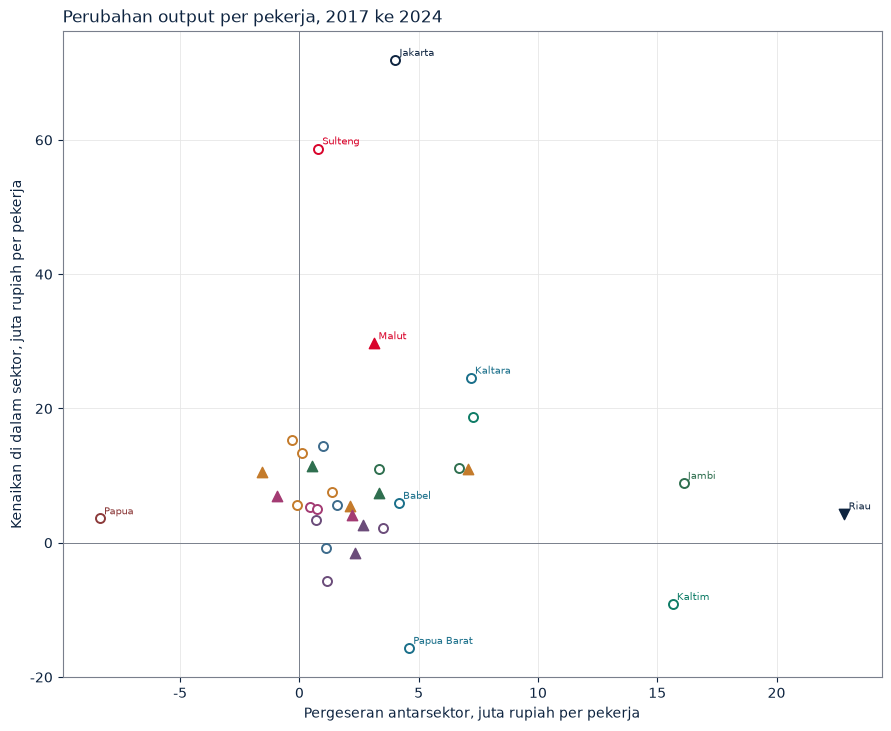

In [8]:
fig, ax = plt.subplots(figsize=(8.8, 7.2), layout="constrained")
for r in prov.itertuples(index=False):
    warna = WARNA_KAT[r.kode_kat]
    if r.uji == "memuat 1":
        ax.scatter(r.ss_between, r.ss_within, s=42, facecolors="white", edgecolors=warna, linewidths=1.4, zorder=3)
    else:
        ax.scatter(r.ss_between, r.ss_within, s=56, c=warna, marker="^" if r.uji == "IRS" else "v", zorder=3)
    if abs(r.ss_between) > 8 or abs(r.ss_within) > 25 or r.kode_kat in list("ABDG"):
        ax.annotate(r.short, (r.ss_between, r.ss_within), textcoords="offset points", xytext=(3, 3), fontsize=7, color=warna)
ax.axhline(0, color=GRAY, lw=0.7)
ax.axvline(0, color=GRAY, lw=0.7)
ax.set_xlabel("Pergeseran antarsektor, juta rupiah per pekerja")
ax.set_ylabel("Kenaikan di dalam sektor, juta rupiah per pekerja")
ax.set_title("Perubahan output per pekerja, 2017 ke 2024", loc="left", color=NAVY)
simpan(fig, "tip_03_shiftshare.png")
